# Długość wiadomości w tokenach BERT

Notebook sprawdza, jaka część tekstu zostaje obcięta przy limicie 512 tokenów modelu `bert-base-uncased`. Wynik decyduje,
czy warto porównywać model z obcięciem do 512 tokenów z podziałem na fragmenty (BELT).

- **Tokenizator:** WordPiece z `bert-base-uncased`, bez obcinania. Z 512 pozycji 2 zajmują tokeny `[CLS]` i `[SEP]`, więc na treść
  zostaje 510 tokenów.
- **Tokeny maskowania:** tokenizator dzieli np. `[URL]` na 5 tokenów (`[`, `ur`, `##l`, `]`). Długości liczone są dla tekstu
  w takiej postaci, w jakiej trafi do modelu bez zmian słownika.
- **Wynik:** udział wiadomości dłuższych niż 510 tokenów, udział obciętych tokenów i liczba fragmentów 510-tokenowych
  potrzebnych w BELT, dla każdego źródła i klasy oraz dla zbiorów train/val/test.

In [ ]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from transformers import AutoTokenizer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import ID_SOURCES, INK_SECONDARY, OOD_SOURCES, load_corpora

RESULTS = ROOT / "results" / "bert_token_lengths"
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.float_format", "{:.2f}".format)

MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 512
CONTENT_LENGTH = MAX_LENGTH - 2  # [CLS] i [SEP]
KIND_COLORS = {"phishing": "#2a78d6", "spam": "#eb6834", "ham": "#1baf7a"}

/home/ubuntu/phishing-thesis/venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Tokenizacja

In [2]:
in_domain, out_of_domain = load_corpora()
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
documents = pd.concat([in_domain.assign(korpus="ID"), out_of_domain.assign(korpus="OOD", split="ood")], ignore_index=True)
documents["n_tokens"] = [len(ids) for ids in tokenizer(documents.text.tolist(), add_special_tokens=False)["input_ids"]]
documents["obcięte"] = (documents.n_tokens - CONTENT_LENGTH).clip(lower=0)
documents["fragmenty"] = np.ceil(documents.n_tokens.clip(lower=1) / CONTENT_LENGTH).astype(int)
mask_tokens = ["[URL]", "[EMAIL_ADDRESS]", "[DOMAIN]", "[FILE_PATH]", "[YEAR]", "[PHONE_NUMBER]"]
print({token: len(tokenizer.tokenize(token)) for token in mask_tokens})
print(documents.groupby("korpus").n_tokens.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (532 > 512). Running this sequence through the model will result in indexing errors


{'[URL]': 4, '[EMAIL_ADDRESS]': 5, '[DOMAIN]': 3, '[FILE_PATH]': 5, '[YEAR]': 3, '[PHONE_NUMBER]': 5}
           count   mean    std  min    50%    90%     95%     99%     max
korpus                                                                   
ID     134469.00 316.86 455.51 2.00 162.00 725.00 1230.00 2257.32 8108.00
OOD      6124.00 126.00  32.79 7.00 129.00 158.00  167.00  226.00  555.00


## Obcięcie według źródła i klasy

`powyżej_510_%` to udział wiadomości dłuższych niż limit, `obcięte_tokeny_%` to udział wszystkich tokenów danej grupy, które
nie zmieszczą się w 512 pozycjach, a `fragmenty_śr` to średnia liczba fragmentów po 510 tokenów, czyli liczba przejść
modelu na wiadomość w BELT.

In [3]:
def summary(frame):
    return pd.Series({
        "liczba": len(frame),
        "mediana": frame.n_tokens.median(),
        "p95": frame.n_tokens.quantile(0.95),
        "max": frame.n_tokens.max(),
        "powyżej_510_%": (frame.n_tokens > CONTENT_LENGTH).mean() * 100,
        "obcięte_tokeny_%": frame["obcięte"].sum() / frame.n_tokens.sum() * 100,
        "fragmenty_śr": frame.fragmenty.mean(),
    })


by_source = documents.groupby(["korpus", "source", "kind"]).apply(summary)
by_source = by_source.reindex([index for name in ID_SOURCES + OOD_SOURCES for index in by_source.index if index[1] == name])
by_source.to_csv(TABLES / "obciecie_wg_zrodla.csv")
display(by_source)

liczba  mediana     p95     max  powyżej_510_%  obcięte_tokeny_%  fragmenty_śr
korpus source   kind                                                                                     
ID     nazario  phishing  9178.00   184.00 1089.00 5915.00          11.51             19.28          1.18
       nigerian phishing  3240.00   537.50  888.05 7379.00          55.43             19.50          1.59
       trec05   ham      32026.00   106.00 1406.00 3745.00          14.33             35.74          1.29
                spam     21822.00   131.00 1293.00 8108.00          16.80             33.42          1.29
       trec06   ham      12238.00   162.00 1109.15 5072.00          16.07             29.56          1.28
                spam      3735.00   143.00  667.00 7426.00          10.84             13.62          1.13
       trec07   ham      24134.00   214.00 1568.05 6341.00          23.38             39.04          1.46
                spam     28096.00   165.00  784.00 4512.00          11.25             19.06          1.17
OOD    ferb     ham        894.00    96.00  152.00  220.00           0.00              0.00          1.00
                phishing  4707.00   133.00  166.00  555.00           0.02              0.01          1.00
       kd10000  ham          5.00    35.00   41.40   42.00           0.00              0.00          1.00
                phishing    55.00    42.00   68.00   68.00           0.00              0.00          1.00
       nebulon  ham         76.00    65.00   95.75  111.00           0.00              0.00          1.00
                phishing    69.00    48.00   70.60   84.00           0.00              0.00          1.00
       zeroday  ham        162.00    72.00  258.90  329.00           0.00              0.00          1.00
                phishing   156.00   124.00  273.75  319.00           0.00              0.00          1.00

In [4]:
by_split = pd.concat({
    split: documents[documents.split == split].groupby("kind").apply(summary) for split in ["train", "val", "test", "ood"]
}, names=["zbiór"])
for split in ["train", "val", "test", "ood"]:
    by_split.loc[(split, "razem"), :] = summary(documents[documents.split == split])
by_split.to_csv(TABLES / "obciecie_wg_zbioru.csv")
display(by_split)

liczba  mediana     p95     max  powyżej_510_%  obcięte_tokeny_%  fragmenty_śr
zbiór kind                                                                                     
train ham      41045.00   149.00 1434.00 5946.00          18.09             36.61          1.35
      phishing  7563.00   214.00 1081.60 7379.00          23.05             22.21          1.30
      spam     32071.00   145.00  943.50 8108.00          13.77             24.61          1.22
val   ham      20515.00   165.00 1325.00 6341.00          16.63             33.92          1.32
      phishing  3602.00   317.50  794.90 2480.00          23.26             13.60          1.27
      spam     16603.00   168.00  787.00 4066.00          10.56             18.66          1.16
test  ham       6838.00   160.00 1771.60 5094.00          19.92             39.80          1.41
      phishing  1253.00   222.00 1022.00 3650.00          21.63             20.29          1.27
      spam      4979.00   182.00 1609.30 5219.00          21.39             41.34          1.43
ood   ham       1137.00    91.00  162.00  329.00           0.00              0.00          1.00
      phishing  4987.00   133.00  168.00  555.00           0.02              0.01          1.00
train razem    80679.00   152.00 1222.00 8108.00          16.83             31.03          1.29
val   razem    40720.00   177.00  997.05 6341.00          14.74             26.54          1.25
test  razem    13070.00   177.00 1598.00 5219.00          20.64             38.75          1.40
ood   razem     6124.00   129.00  167.00  555.00           0.02              0.01          1.00

## Rozkład długości

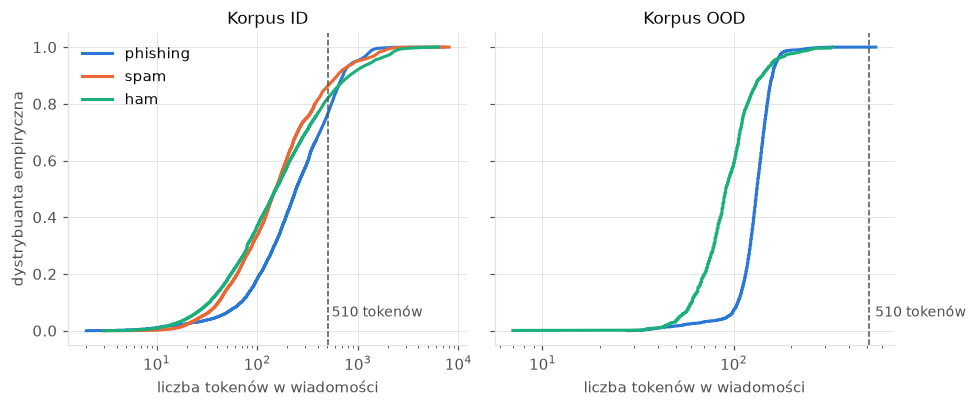

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for axis, korpus in zip(axes, ["ID", "OOD"]):
    subset = documents[documents.korpus == korpus]
    for kind, color in KIND_COLORS.items():
        lengths = np.sort(subset.loc[subset.kind == kind, "n_tokens"].to_numpy())
        if len(lengths):
            axis.plot(lengths, np.arange(1, len(lengths) + 1) / len(lengths), color=color, linewidth=2, label=kind)
    axis.axvline(CONTENT_LENGTH, color=INK_SECONDARY, linewidth=1, linestyle="--")
    axis.text(CONTENT_LENGTH * 1.08, 0.05, "510 tokenów", color=INK_SECONDARY, fontsize=9)
    axis.set_xscale("log")
    axis.set_xlabel("liczba tokenów w wiadomości")
    axis.set_title(f"Korpus {korpus}")
axes[0].set_ylabel("dystrybuanta empiryczna")
axes[0].legend(loc="upper left")
figure.tight_layout()
figure.savefig(FIGURES / "dlugosc_tokenow.pdf")
plt.show()